# Management Insights & Reporting Framework

## Purpose of this Notebook
This notebook synthesizes analytical findings into executive-level insights, decision matrices, and risk reporting frameworks. 

The focus is on:
- Executive portfolio monitoring and KPI benchmarks.
- Portfolio steering mechanisms (Growth vs. Risk vs. Return).
- Operational decision frameworks when Early Warning Indicators (EWIs) trigger alerts.
- Data governance and policy recommendations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import os

# Styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
sns.set_context("talk")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Load Data
use_cols = [
    "SK_ID_CURR",
    "TARGET",
    "AMT_CREDIT",
    "AMT_INCOME_TOTAL",
    "DAYS_BIRTH",
    "EXT_SOURCE_2",
    "CNT_FAM_MEMBERS",
    "REGION_RATING_CLIENT"
]

df = pd.read_csv(
    "../archive/feature_matrix.csv",
    usecols=use_cols,
    nrows=100_000
)

# 2. Data Cleansing & Derived Metrics
df["TARGET"] = df["TARGET"].replace(-999, np.nan)
df["AGE_YEARS"] = (-df["DAYS_BIRTH"] / 365.25).round(1)

print(f"Portfolio analyzed: {len(df):,} applications | Observed loans: {df['TARGET'].notnull().sum():,}")

Portfolio analyzed: 100,000 applications | Observed loans: 86,173


In [2]:
# 3. Executive KPI Snapshot
total_apps = len(df)
observed_apps = int(df["TARGET"].notnull().sum())
baseline_default = df["TARGET"].mean()
avg_credit = df["AMT_CREDIT"].mean()
total_credit = df["AMT_CREDIT"].sum()
avg_income = df["AMT_INCOME_TOTAL"].mean()

kpi_snapshot = pd.DataFrame({
    "Executive KPI": [
        "Total Portfolio Applications",
        "Observed (Labeled) Records",
        "Portfolio Default Rate (Baseline)",
        "Average Credit Line Requested",
        "Total Exposure Sample",
        "Average Annual Income"
    ],
    "Value": [
        f"{total_apps:,}",
        f"{observed_apps:,}",
        f"{baseline_default:.2%}",
        f"${avg_credit:,.2f}",
        f"${total_credit*1e-6:,.1f}M",
        f"${avg_income:,.2f}"
    ]
})

kpi_snapshot

,Executive KPI,Value
0,Total Portfolio Applications,"100,000"
1,Observed (Labeled) Records,"86,173"
2,Portfolio Default Rate (Baseline),8.06%
3,Average Credit Line Requested,"$586,964.74"
4,Total Exposure Sample,"$58,696.5M"
5,Average Annual Income,"$170,680.03"


## Executive KPI Snapshot – Management Interpretation

- **Default Rate (8.06%):** Serves as the primary risk benchmark for underwriting calibrations.
- **Exposure Base:** Informs capital provisioning requirements and risk-weighted asset (RWA) allocations.
- **Affordability Ratio:** Compares credit requested against mean income to gauge market penetration.

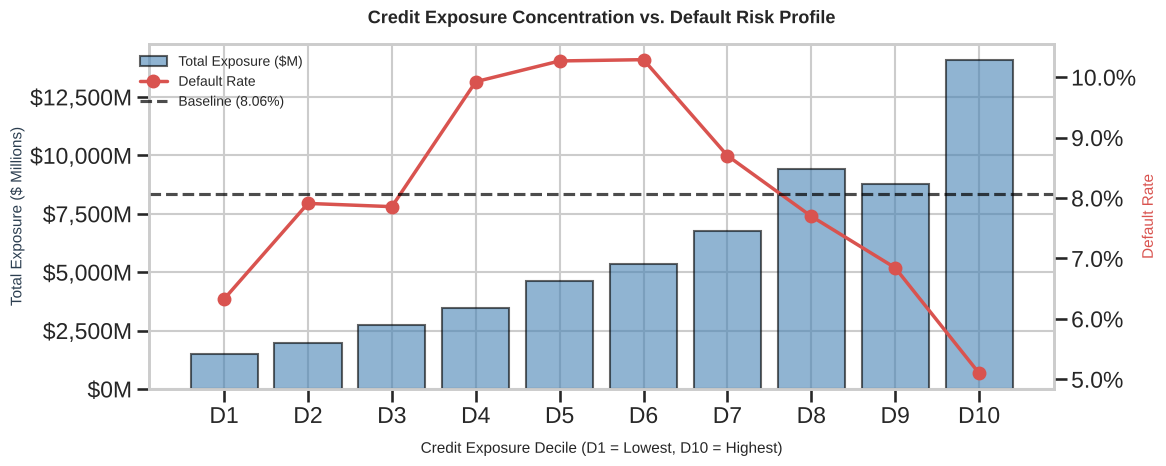

In [3]:
# 4. Exposure vs. Risk Distribution (Decile Analysis)
df["CREDIT_DECILE"] = pd.qcut(df["AMT_CREDIT"], q=10, labels=[f"D{i}" for i in range(1, 11)])

exposure_kpi = (
    df.groupby("CREDIT_DECILE", observed=True)
      .agg(
          Applications=("SK_ID_CURR", "count"),
          Total_Exposure=("AMT_CREDIT", "sum"),
          Default_Rate=("TARGET", "mean")
      )
      .reset_index()
)

# Visualization: Exposure vs Default Rate
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Axis: Total Exposure (Volume)
color_bar = "#4682B4"
ax1.bar(
    exposure_kpi["CREDIT_DECILE"],
    exposure_kpi["Total_Exposure"] / 1e6,
    color=color_bar,
    alpha=0.6,
    edgecolor="black",
    label="Total Exposure ($M)"
)
ax1.set_xlabel("Credit Exposure Decile (D1 = Lowest, D10 = Highest)", fontsize=11, labelpad=10)
ax1.set_ylabel("Total Exposure ($ Millions)", fontsize=11, color="#2c3e50")
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x:,.0f}M"))

# Secondary Axis: Default Rate
ax2 = ax1.twinx()
color_line = "#D9534F"
ax2.plot(
    exposure_kpi["CREDIT_DECILE"],
    exposure_kpi["Default_Rate"],
    color=color_line,
    marker="o",
    linewidth=2.5,
    label="Default Rate"
)
ax2.axhline(baseline_default, color="black", linestyle="--", alpha=0.7, label=f"Baseline ({baseline_default:.2%})")
ax2.set_ylabel("Default Rate", fontsize=11, color=color_line)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
ax2.grid(False)

plt.title("Credit Exposure Concentration vs. Default Risk Profile", fontsize=13, pad=15, fontweight="bold")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88), fontsize=10)
plt.tight_layout()
plt.savefig("../reports/figures/risk_vs_exposure.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# 5. Management Policy & Action Matrix
policy_matrix = pd.DataFrame([
    {
        "Trigger / Segment": "External Score Q1 (Lowest Bureau Score)",
        "Observed Risk": "> 15.0% Default Rate",
        "Policy Action": "Hard cut-off / Automated rejection for uncollateralized loans",
        "Owner": "Credit Risk Policy"
    },
    {
        "Trigger / Segment": "Young Demographics (< 32 yrs)",
        "Observed Risk": "11.2% Default Rate (baseline 8.06%)",
        "Policy Action": "Lower initial credit limits & mandate co-signer / proof of steady employment",
        "Owner": "Underwriting"
    },
    {
        "Trigger / Segment": "Top Exposure Deciles (D9 - D10)",
        "Observed Risk": "Lowest default rates (6.9% / 5.1%) but the largest exposure share",
        "Policy Action": "Mandate manual senior underwriter review & strict DTI validation",
        "Owner": "Risk Committee"
    },
    {
        "Trigger / Segment": "Low Income Cohorts (Tier 1)",
        "Observed Risk": "8.3% Default Rate, close to baseline (weak signal on its own)",
        "Policy Action": "No blanket cap; apply affordability (DBR) checks together with bureau score and age",
        "Owner": "Product & Risk"
    }
])

policy_matrix

,Trigger / Segment,Observed Risk,Policy Action,Owner
0,External Score Q1 (Lowest Bureau Score),> 15.0% Default Rate,Hard cut-off / Automated rejection for uncolla...,Credit Risk Policy
1,Young Demographics (< 32 yrs),11.2% Default Rate (baseline 8.06%),Lower initial credit limits & mandate co-signe...,Underwriting
2,Top Exposure Deciles (D9 - D10),Lowest default rates (6.9% / 5.1%) but the lar...,Mandate manual senior underwriter review & str...,Risk Committee
3,Low Income Cohorts (Tier 1),"8.3% Default Rate, close to baseline (weak sig...",No blanket cap; apply affordability (DBR) chec...,Product & Risk


## Portfolio Steering & Decision Framework

### Structured Escalation Workflow
1. **Signal Identification:** Monthly EWI dashboard flags segments deviating by more than `+1.5 pp` from baseline.
2. **Segment Isolation:** Deep-dive into regional concentration, channel origination, and demographic mix.
3. **Policy Adjustment:** Recalibrate credit score cut-offs, loan-to-income (LTI) limits, or pricing spreads.
4. **Impact Monitoring:** Track vintage delinquency curves (30+ / 60+ / 90+ DPD) for 3 consecutive months.

### Collaboration Model
| Domain | Data Science Role | Risk Management Role |
| :--- | :--- | :--- |
| **Model Governance** | PSI/CSI stability monitoring, Gini/AUC validation | Setting business cut-offs, policy approval |
| **Strategy Calibration** | Optimization algorithms, uplift modeling | Margin targets, risk appetite limits |
| **Portfolio Monitoring**| Pipeline maintenance, automated feature auditing | Quarterly loss forecasting, provisioning |

## Governance Considerations & Limitations

- **Data Interpretation:** The analysis uses the public Home Credit dataset, where `TARGET` flags payment difficulties; it is not the loss history of a live portfolio. All cut-offs must be validated against production default data (vintages, loss forecasts) before policy execution.
- **Monitoring Frequency:** High-ticket exposures and younger demographic cohorts should be reviewed on a monthly vintage basis.

## Key Takeaways
1. **Concentration over Frequency:** While default frequency peaks in mid-sized loans and is lowest for the largest ones, absolute loss exposure resides primarily in high credit brackets ($>\$1\text{M}$).
2. **Predictive Strength of External Scoring:** `EXT_SOURCE_2` demonstrates strong risk separation, making it the primary lever for risk-based pricing.